# Pertemuan 6: Eksplorasi Struktur Data dengan Clustering dan Reduksi Dimensi

Pertemuan sebelumnya memakai label untuk melatih model. Notebook ini melihat data tanpa label untuk menjawab tiga pertanyaan:

1. Apakah pesan email membentuk kelompok alami, dan apakah kelompok tersebut sesuai dengan kelas Ham, Phish, dan Spam?
2. Ciri apa yang membedakan setiap kelompok?
3. Apakah reduksi dimensi membantu klasifikasi?

Seluruh analisis hanya memakai data training. Data testing tetap disimpan untuk evaluasi akhir.

# A. Data

Dataset, preprocessing, dan pembagian data sama dengan Pertemuan 3 sampai 5. Sel berikut memuat dataset, menjalankan preprocessing, lalu menyisihkan data testing. Hanya data training (223.152 pesan) yang disimpan.

In [1]:
import sys
import subprocess
import time
import gc

try:
    from datasets import load_dataset
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'datasets'])
    from datasets import load_dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold

RANDOM_STATE = 42
DATASET_NAME = 'locuoco/the-biggest-spam-ham-phish-email-dataset-300000'
LABEL_NAMES = {0: 'Ham', 1: 'Phish', 2: 'Spam'}
CLASS_IDS = [0, 1, 2]
CLASS_ORDER = [LABEL_NAMES[c] for c in CLASS_IDS]
CLASS_COLORS = {'Ham': '#2a78d6', 'Phish': '#eb6834', 'Spam': '#1baf7a'}

raw_df = load_dataset(DATASET_NAME, split='train').to_pandas()
data = raw_df[['text', 'label']].dropna(subset=['text', 'label']).copy()
data = data[data['label'].isin(CLASS_IDS)].copy()
data['label'] = data['label'].astype(int)
data['clean_text'] = data['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
data = data[data['clean_text'].ne('')].copy()
data['dedup_key'] = data['clean_text'].str.lower()
labels_per_key = data.groupby('dedup_key')['label'].nunique()
data = data.loc[~data['dedup_key'].isin(labels_per_key[labels_per_key.gt(1)].index)]
df_clean = (
    data.drop_duplicates(subset=['dedup_key'], keep='first')
    [['clean_text', 'label']]
    .rename(columns={'clean_text': 'text'})
    .reset_index(drop=True)
)
del raw_df, data
gc.collect()

# Bagian testing (20%) tidak disimpan: data testing tidak dipakai pada notebook ini.
X_train, _, y_train, _ = train_test_split(
    df_clean['text'], df_clean['label'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df_clean['label']
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.to_numpy()
del df_clean
gc.collect()

print(f'Jumlah data training: {len(X_train):,} (Pertemuan 3: 223,152)')
print(f'Versi library      : scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}')

README.md:   0%|          | 0.00/990 [00:00<?, ?B/s]

df.csv: reconstructing file:   0%|          |  0.00B /  631MB            

df.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/365448 [00:00<?, ? examples/s]

Jumlah data training: 223,152 (Pertemuan 3: 223,152)
Versi library      : scikit-learn 1.6.1, pandas 2.2.3, numpy 2.4.6


# B. Persiapan Fitur

| Aspek | Keputusan | Alasan |
| --- | --- | --- |
| Fitur | TF-IDF unigram, kata yang muncul di minimal 5 pesan (`min_df=5`), `sublinear_tf=True` | Kata yang sangat jarang tidak dapat membentuk kelompok. Membuangnya juga mengurangi memori dan waktu reduksi dimensi. |
| Skala | Tidak memakai `StandardScaler`. TF-IDF sudah menormalisasi setiap pesan, dan setelah reduksi dimensi setiap pesan dinormalisasi kembali menjadi panjang 1 (`Normalizer`). | `StandardScaler` mengurangi rata-rata setiap kolom, sehingga matriks *sparse* berukuran ratusan ribu kolom menjadi matriks padat yang tidak muat di memori. Normalisasi panjang 1 membuat jarak Euclidean pada K-Means setara dengan kemiripan kosinus antar pesan. |
| Data | Data training saja | Data testing tidak boleh memengaruhi analisis apa pun. Pada uji manfaat reduksi dimensi (bagian F), vectorizer dan reduksi dimensi dilatih ulang pada data latih setiap fold. |

Sel berikut membentuk matriks TF-IDF dari data training.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

start = time.perf_counter()
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 1), min_df=5, sublinear_tf=True, dtype=np.float32)
X_tfidf = tfidf.fit_transform(X_train)
TERMS = tfidf.get_feature_names_out()
print(f'Matriks TF-IDF: {X_tfidf.shape[0]:,} pesan × {X_tfidf.shape[1]:,} kata ({time.perf_counter() - start:.0f} detik)')

Matriks TF-IDF: 223,152 pesan × 143,172 kata (61 detik)


# C. Reduksi Dimensi

## C.1 TruncatedSVD

PCA mengurangi rata-rata setiap kolom sebelum mencari komponen utama. Pada matriks TF-IDF, langkah ini mengubah matriks *sparse* menjadi matriks padat yang tidak muat di memori. Karena itu, notebook ini memakai **TruncatedSVD**, yaitu PCA tanpa pengurangan rata-rata yang dapat bekerja langsung pada matriks *sparse*. Pada data teks, metode ini juga dikenal sebagai *Latent Semantic Analysis*.

Sel berikut melatih TruncatedSVD dengan 200 komponen, lalu menampilkan *scree plot*: varians yang dijelaskan setiap komponen dan varians kumulatifnya. Langkah ini membutuhkan sekitar 10 menit.

TruncatedSVD selesai dalam 1.3 menit


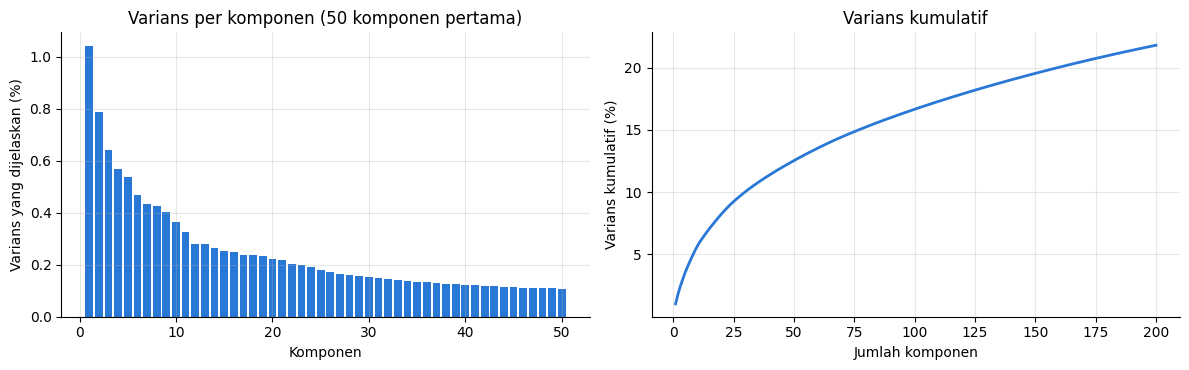

,jumlah komponen,varians kumulatif (%)
0,2,1.830000
1,10,5.670000
2,50,12.530000
3,100,16.660000
4,200,21.790001


200 komponen menjelaskan 21.8% varians dari 143,172 kata. Aturan umum 90–95% varians tidak dapat dipakai pada data teks, karena aturan tersebut membutuhkan ribuan komponen. Clustering pada bagian D memakai 100 komponen pertama. Jumlah ini umum dipakai pada *Latent Semantic Analysis* dan menjaga K-Means tetap cepat. Pengaruh jumlah komponen terhadap klasifikasi diuji pada bagian F.

In [3]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

N_COMPONENTS = 200
start = time.perf_counter()
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
Z = svd.fit_transform(X_tfidf)
print(f'TruncatedSVD selesai dalam {(time.perf_counter() - start) / 60:.1f} menit')

ratio = svd.explained_variance_ratio_
cumulative = np.cumsum(ratio)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(np.arange(1, 51), ratio[:50] * 100, color='#2a78d6', width=0.8)
axes[0].set_title('Varians per komponen (50 komponen pertama)')
axes[0].set_xlabel('Komponen')
axes[0].set_ylabel('Varians yang dijelaskan (%)')
axes[1].plot(np.arange(1, N_COMPONENTS + 1), cumulative * 100, color='#2a78d6', linewidth=2)
axes[1].set_title('Varians kumulatif')
axes[1].set_xlabel('Jumlah komponen')
axes[1].set_ylabel('Varians kumulatif (%)')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    'jumlah komponen': [2, 10, 50, 100, 200],
    'varians kumulatif (%)': [round(cumulative[k - 1] * 100, 2) for k in [2, 10, 50, 100, 200]],
}))
display(Markdown(
    f"200 komponen menjelaskan {cumulative[-1] * 100:.1f}% varians dari {X_tfidf.shape[1]:,} kata. "
    "Aturan umum 90–95% varians tidak dapat dipakai pada data teks, karena aturan tersebut membutuhkan ribuan komponen. "
    "Clustering pada bagian D memakai 100 komponen pertama. Jumlah ini umum dipakai pada *Latent Semantic Analysis* "
    "dan menjaga K-Means tetap cepat. Pengaruh jumlah komponen terhadap klasifikasi diuji pada bagian F."
))

## C.2 Visualisasi 2D

Sel berikut menampilkan 6.000 pesan acak dalam dua dimensi dengan dua metode:

1. **Dua komponen pertama TruncatedSVD**, yang menjelaskan varians terbesar.
2. **t-SNE** dari 100 komponen pertama. t-SNE menjaga pesan yang mirip tetap berdekatan, tetapi jarak antar kelompok pada grafik t-SNE tidak bermakna. t-SNE hanya dipakai untuk visualisasi, bukan sebagai fitur model.

Warna menunjukkan label asli. Label tidak dipakai saat membentuk kedua grafik.

t-SNE selesai dalam 70 detik


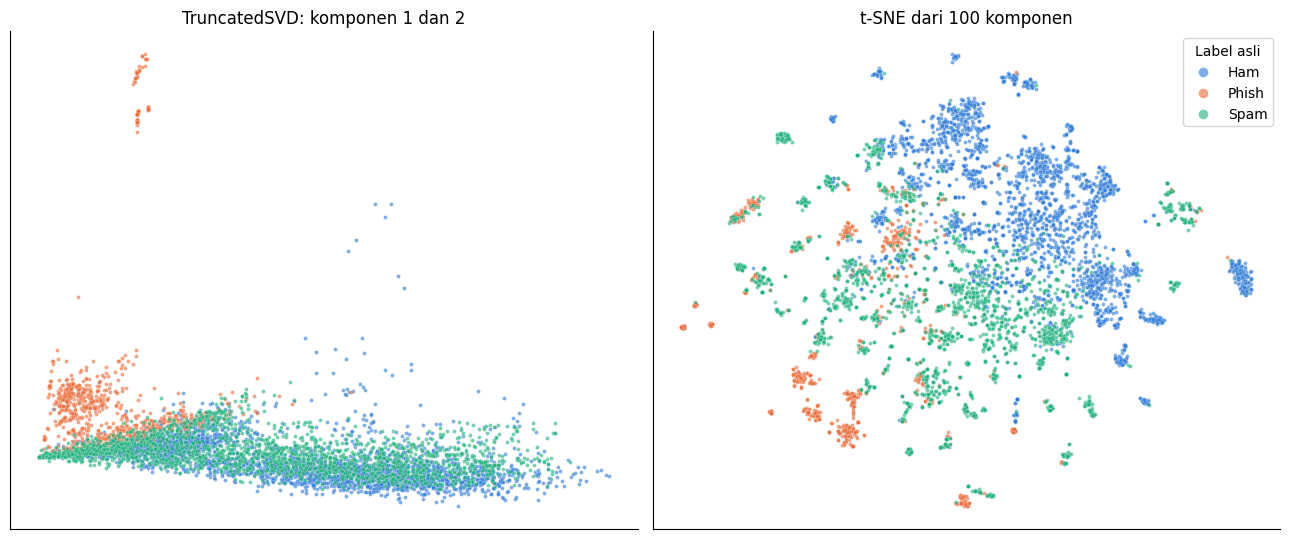

In [4]:
from sklearn.manifold import TSNE

N_CLUSTER_COMPONENTS = 100
Z_cluster = Normalizer().fit_transform(Z[:, :N_CLUSTER_COMPONENTS])
rng = np.random.default_rng(RANDOM_STATE)
plot_index = rng.choice(len(y_train), size=min(6000, len(y_train)), replace=False)

start = time.perf_counter()
tsne_xy = TSNE(n_components=2, random_state=RANDOM_STATE, init='pca', perplexity=30).fit_transform(Z_cluster[plot_index])
print(f't-SNE selesai dalam {time.perf_counter() - start:.0f} detik')

svd_xy = Z[plot_index, :2]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, xy, title in [(axes[0], svd_xy, 'TruncatedSVD: komponen 1 dan 2'), (axes[1], tsne_xy, 't-SNE dari 100 komponen')]:
    for class_id in CLASS_IDS:
        mask = y_train[plot_index] == class_id
        name = LABEL_NAMES[class_id]
        ax.scatter(xy[mask, 0], xy[mask, 1], s=8, alpha=0.6, color=CLASS_COLORS[name],
                   edgecolors='white', linewidths=0.2, label=name)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[['top', 'right']].set_visible(False)
axes[1].legend(title='Label asli', markerscale=2.5, loc='best')
plt.tight_layout()
plt.show()

# D. Clustering

## D.1 Memilih Jumlah Cluster

K-Means dipilih sebagai algoritma utama karena cepat pada ratusan ribu pesan dan mudah diprofilkan melalui pusat cluster. K-Means dijalankan untuk K = 2 sampai 12 pada 100 komponen TruncatedSVD yang telah dinormalisasi. Setiap K dinilai dengan empat metrik:

| Metrik | Arti | Nilai yang lebih baik |
| --- | --- | --- |
| Inertia (*elbow*) | Jumlah kuadrat jarak setiap pesan ke pusat cluster-nya | Titik siku pada grafik |
| Silhouette | Seberapa dekat pesan dengan cluster-nya dibandingkan cluster lain (−1 sampai 1) | Lebih tinggi |
| Davies–Bouldin | Rata-rata kemiripan setiap cluster dengan cluster yang paling mirip dengannya | Lebih rendah |
| Calinski–Harabasz | Rasio sebaran antar cluster terhadap sebaran di dalam cluster | Lebih tinggi |

Silhouette dihitung pada 10.000 pesan acak, karena perhitungannya membandingkan setiap pasangan pesan. K dipilih berdasarkan silhouette tertinggi.

Sebagai pemeriksaan tambahan, label asli dibandingkan dengan hasil cluster memakai *Adjusted Rand Index* (ARI) dan *Normalized Mutual Information* (NMI). Nilai 0 berarti cluster tidak berhubungan dengan label, dan nilai 1 berarti cluster sama persis dengan label. Kedua metrik ini tidak dipakai untuk memilih K.

Langkah ini membutuhkan sekitar 5 menit.

,K,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
0,2,166153.9219,0.0801,3.3058,19615.304688,0.0708,0.1401
1,3,160633.6250,0.0761,3.4795,13973.436523,0.1327,0.2119
2,4,155856.1562,0.0906,3.6336,11884.011719,0.1878,0.2525
3,5,151725.5469,0.0862,3.4360,10673.819336,0.1857,0.2714
4,6,149117.2656,0.0479,3.6631,9468.828125,0.1564,0.2563
5,7,146615.8281,0.0516,3.5764,8660.216797,0.1939,0.3192
6,8,143114.9844,0.0715,3.3014,8384.680664,0.1548,0.2665
7,9,141313.3438,0.0762,3.1858,7785.697754,0.1629,0.2763
8,10,139005.3281,0.0691,3.1178,7446.610352,0.1363,0.2727
9,11,136982.7031,0.0760,3.0263,7130.346191,0.1356,0.2871


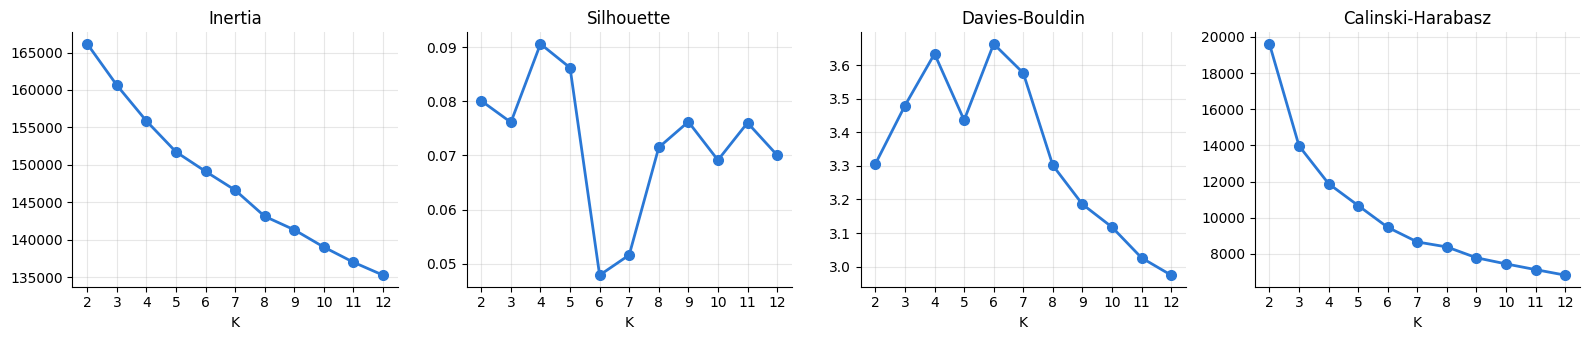

Silhouette tertinggi diperoleh pada **K = 4** (0.0906). Menurut panduan Kaufman dan Rousseeuw (di bawah 0,25: tidak ada struktur yang kuat; 0,25–0,50: struktur lemah; di atas 0,50: struktur cukup jelas), nilai ini berarti **tidak ada struktur cluster yang kuat**. Cluster yang paling sesuai dengan label asli terdapat pada K = 7 (NMI 0.3192). Bagian D.2 memprofilkan cluster pada K = 4 dan pada K = 7 untuk melihat kelompok yang lebih rinci.

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)

K_RANGE = list(range(2, 13))
silhouette_index = rng.choice(len(y_train), size=min(10_000, len(y_train)), replace=False)
kmeans_models, k_rows = {}, []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(Z_cluster)
    kmeans_models[k] = model
    k_rows.append({
        'K': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(Z_cluster[silhouette_index], model.labels_[silhouette_index]),
        'Davies-Bouldin': davies_bouldin_score(Z_cluster, model.labels_),
        'Calinski-Harabasz': calinski_harabasz_score(Z_cluster, model.labels_),
        'ARI': adjusted_rand_score(y_train, model.labels_),
        'NMI': normalized_mutual_info_score(y_train, model.labels_),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, metric in zip(axes, ['Inertia', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']):
    ax.plot(k_table['K'], k_table[metric], marker='o', markersize=7, linewidth=2, color='#2a78d6')
    ax.set_title(metric)
    ax.set_xlabel('K')
    ax.set_xticks(K_RANGE)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

K_SILHOUETTE = int(k_table.loc[k_table['Silhouette'].idxmax(), 'K'])
K_DETAIL = int(k_table.loc[k_table['NMI'].idxmax(), 'K'])
best_silhouette = k_table['Silhouette'].max()
strength = ('tidak ada struktur cluster yang kuat' if best_silhouette < 0.25
            else 'struktur cluster lemah' if best_silhouette < 0.5 else 'struktur cluster cukup jelas')
display(Markdown(
    f"Silhouette tertinggi diperoleh pada **K = {K_SILHOUETTE}** ({best_silhouette:.4f}). "
    f"Menurut panduan Kaufman dan Rousseeuw (di bawah 0,25: tidak ada struktur yang kuat; 0,25–0,50: struktur lemah; "
    f"di atas 0,50: struktur cukup jelas), nilai ini berarti **{strength}**. "
    f"Cluster yang paling sesuai dengan label asli terdapat pada K = {K_DETAIL} (NMI {k_table['NMI'].max():.4f}). "
    f"Bagian D.2 memprofilkan cluster pada K = {K_SILHOUETTE}"
    + (f" dan pada K = {K_DETAIL} untuk melihat kelompok yang lebih rinci." if K_DETAIL != K_SILHOUETTE else '.')
))

## D.2 Profil Cluster

Setiap cluster diprofilkan dengan ciri berikut:

| Kolom | Arti |
| --- | --- |
| Ham, Phish, Spam (%) | Komposisi label asli di dalam cluster. |
| Kemurnian | Persentase kelas terbanyak di dalam cluster. |
| Kata khas | Delapan kata dengan bobot tertinggi pada pusat cluster. |
| Token `escape…` (%) | Pesan yang memuat token pengganti seperti `escapenumber`. Sebagian sumber data mengganti angka dengan token ini. |
| Angka (%) | Pesan yang memuat angka asli, misalnya `2008`. |
| Kata `enron` (%) | Pesan yang memuat kata `enron`. Contoh data pada Pertemuan 3 menunjukkan bahwa sebagian Ham berasal dari korespondensi kerja perusahaan Enron. |
| Median kata | Median jumlah kata per pesan. |

Kolom `escape…`, angka, dan `enron` dipakai untuk memeriksa apakah cluster mengikuti **sumber data**, bukan hanya isi pesan. Nama cluster dibentuk otomatis dari kelas terbanyak dan tiga kata khas pertama.

In [6]:
text_lower = X_train.str.lower()
has_escape = text_lower.str.contains(r'\bescape\w+', regex=True).to_numpy()
has_digit = text_lower.str.contains(r'\b\d+\b', regex=True).to_numpy()
has_enron = text_lower.str.contains(r'\benron\b', regex=True).to_numpy()
word_count = X_train.str.count(r'\S+').to_numpy()


def cluster_profile(k):
    model = kmeans_models[k]
    center_terms = model.cluster_centers_ @ svd.components_[:N_CLUSTER_COMPONENTS]
    rows = []
    for c in range(k):
        mask = model.labels_ == c
        share = np.bincount(y_train[mask], minlength=3) / mask.sum()
        dominant = CLASS_ORDER[int(share.argmax())]
        top_terms = TERMS[np.argsort(-center_terms[c])[:8]]
        rows.append({
            'cluster': c,
            'nama': f"{dominant} ({share.max() * 100:.0f}%): {', '.join(top_terms[:3])}",
            'jumlah pesan': int(mask.sum()),
            'Ham (%)': share[0] * 100, 'Phish (%)': share[1] * 100, 'Spam (%)': share[2] * 100,
            'kemurnian (%)': share.max() * 100,
            'kata khas': ' '.join(top_terms),
            'token escape… (%)': has_escape[mask].mean() * 100,
            'angka (%)': has_digit[mask].mean() * 100,
            'kata enron (%)': has_enron[mask].mean() * 100,
            'median kata': int(np.median(word_count[mask])),
        })
    return pd.DataFrame(rows).sort_values('jumlah pesan', ascending=False).reset_index(drop=True)


profiles = {}
for k in dict.fromkeys([K_SILHOUETTE, K_DETAIL]):
    profiles[k] = cluster_profile(k)
    display(Markdown(f'### Profil cluster, K = {k}'))
    display(profiles[k].round(1))

### Profil cluster, K = 4

,cluster,nama,jumlah pesan,Ham (%),Phish (%),Spam (%),kemurnian (%),kata khas,token escape… (%),angka (%),kata enron (%),median kata
0,1,"Ham (64%): the, to, and",93864,63.6,0.0,36.4,63.6,the to and escapenumber of you in is,68.6,14.8,17.8,182
1,0,"Spam (65%): escapenumber, http, com",67601,25.0,9.6,65.4,65.4,escapenumber http com escapelong www to the you,65.7,15.1,7.1,72
2,2,"Ham (58%): escapenumber, please, message",44326,57.7,23.6,18.7,57.7,escapenumber please message sent subject origi...,59.0,26.7,21.4,119
3,3,"Phish (100%): 2008, aug, 06",17361,0.1,99.7,0.2,99.7,2008 aug 06 wed 07 thu 0000 0300,0.0,99.7,0.0,39


### Profil cluster, K = 7

,cluster,nama,jumlah pesan,Ham (%),Phish (%),Spam (%),kemurnian (%),kata khas,token escape… (%),angka (%),kata enron (%),median kata
0,4,"Spam (70%): escapenumber, http, com",46689,18.2,12.2,69.6,69.6,escapenumber http com escapelong www info net to,60.3,17.2,6.3,63
1,5,"Spam (80%): to, the, you",41237,20.0,0.0,80.0,80.0,to the you your and escapenumber of for,68.9,14.8,5.4,151
2,2,"Ham (99%): the, to, escapenumber",32619,98.8,0.0,1.2,98.8,the to escapenumber and of you for in,62.1,26.2,44.3,178
3,6,"Ham (72%): the, to, and",32582,72.0,0.0,28.0,72.0,the to and escapenumber of it is in,74.4,2.9,1.3,183
4,3,"Phish (38%): email, please, escapenumber",29507,32.7,38.4,28.9,38.4,email please escapenumber information us new o...,37.0,41.9,10.9,145
5,1,"Ham (86%): escapenumber, original, sent",23237,86.2,0.1,13.7,86.2,escapenumber original sent message subject enr...,98.7,0.3,33.0,76
6,0,"Phish (100%): 2008, aug, 06",17281,0.1,99.8,0.2,99.8,2008 aug 06 wed 07 thu 0000 0300,0.0,99.8,0.0,39


## D.3 Pembanding: Agglomerative Clustering

*Agglomerative clustering* (metode Ward) menggabungkan pesan yang paling mirip secara bertahap sampai tersisa K cluster. Metode ini tidak bergantung pada titik awal acak seperti K-Means, tetapi membutuhkan memori sebanding dengan kuadrat jumlah pesan. Karena itu, perbandingan dilakukan pada 5.000 pesan acak dengan K yang sama.

In [7]:
from sklearn.cluster import AgglomerativeClustering

compare_index = rng.choice(len(y_train), size=min(5000, len(y_train)), replace=False)
Z_small = Z_cluster[compare_index]
agglomerative_labels = AgglomerativeClustering(n_clusters=K_SILHOUETTE, linkage='ward').fit_predict(Z_small)
kmeans_labels = kmeans_models[K_SILHOUETTE].labels_[compare_index]

compare_table = pd.DataFrame({
    'algoritma': ['K-Means', 'Agglomerative (Ward)'],
    'Silhouette': [silhouette_score(Z_small, kmeans_labels), silhouette_score(Z_small, agglomerative_labels)],
    'ARI terhadap label asli': [adjusted_rand_score(y_train[compare_index], kmeans_labels),
                                adjusted_rand_score(y_train[compare_index], agglomerative_labels)],
})
display(compare_table.round(4))
agreement = adjusted_rand_score(kmeans_labels, agglomerative_labels)
display(Markdown(
    f"Kesamaan hasil kedua algoritma (ARI antara keduanya) adalah {agreement:.4f}. "
    + ('Kedua algoritma membentuk kelompok yang mirip, sehingga struktur yang ditemukan tidak bergantung pada satu algoritma.'
       if agreement >= 0.5 else
       'Kedua algoritma membentuk kelompok yang cukup berbeda, sehingga struktur cluster bergantung pada algoritma yang dipakai.')
))

,algoritma,Silhouette,ARI terhadap label asli
0,K-Means,0.0930,0.1955
1,Agglomerative (Ward),0.0655,0.2081


Kesamaan hasil kedua algoritma (ARI antara keduanya) adalah 0.3836. Kedua algoritma membentuk kelompok yang cukup berbeda, sehingga struktur cluster bergantung pada algoritma yang dipakai.

# E. Interpretasi dan Batasan

Sel berikut merangkum hasil clustering dan menghitung ciri sumber data untuk setiap kelas.

In [8]:
detail = profiles[K_DETAIL]
pure = detail[detail['kemurnian (%)'] >= 90]
source_table = pd.DataFrame({
    'token escape… (%)': [has_escape[y_train == c].mean() * 100 for c in CLASS_IDS],
    'angka (%)': [has_digit[y_train == c].mean() * 100 for c in CLASS_IDS],
    'kata enron (%)': [has_enron[y_train == c].mean() * 100 for c in CLASS_IDS],
}, index=CLASS_ORDER)
display(Markdown('### Ciri sumber data per kelas'))
display(source_table.round(1))

phish_escape = source_table.loc['Phish', 'token escape… (%)']
other_escape = source_table.drop(index='Phish')['token escape… (%)'].min()
artifact_found = phish_escape < 5 and other_escape > 30
interpretation = f'''
### Interpretasi

1. **Struktur cluster.** Silhouette tertinggi adalah {best_silhouette:.4f} (K = {K_SILHOUETTE}), sehingga {strength}. Pesan email tidak terbagi menjadi kelompok yang terpisah tegas.
2. **Hubungan dengan label.** Pada K = {K_DETAIL}, {len(pure)} dari {K_DETAIL} cluster memiliki kemurnian minimal 90%, mencakup {pure['jumlah pesan'].sum():,} pesan ({pure['jumlah pesan'].sum() / len(y_train) * 100:.1f}% data training). Cluster lainnya mencampur beberapa kelas.
3. **Sumber data.** Token `escape…` muncul pada {source_table.loc['Ham', 'token escape… (%)']:.1f}% Ham, {phish_escape:.1f}% Phish, dan {source_table.loc['Spam', 'token escape… (%)']:.1f}% Spam. Angka asli muncul pada {source_table.loc['Ham', 'angka (%)']:.1f}% Ham, {source_table.loc['Phish', 'angka (%)']:.1f}% Phish, dan {source_table.loc['Spam', 'angka (%)']:.1f}% Spam. {'Format angka berbeda antar kelas: sumber data Phish tidak mengganti angka dengan token pengganti.' if artifact_found else 'Format angka tidak berbeda tegas antar kelas.'}
'''
if artifact_found:
    interpretation += '''
**Hipotesis 4.** Model dapat mengenali Phish dari format angka sumber datanya, bukan dari isi pesan. Email nyata tidak memiliki perbedaan format seperti ini, sehingga performa model pada data baru dapat lebih rendah. Hipotesis ini diuji pada Pertemuan 7 dengan menyeragamkan format angka.
'''
interpretation += '''
**Batasan.**

- Clustering memakai TF-IDF unigram dan 100 komponen TruncatedSVD. Representasi lain dapat menghasilkan cluster yang berbeda.
- K-Means mengasumsikan cluster berbentuk bulat dengan ukuran sebanding, sedangkan kelompok pesan email tidak harus berbentuk seperti itu.
- Silhouette dan perbandingan dengan Agglomerative Clustering dihitung pada sampel acak, bukan seluruh data.
- Nama cluster dibentuk otomatis dari kelas terbanyak dan kata khas, sehingga perlu dibaca bersama tabel profil.
'''
display(Markdown(interpretation))

### Ciri sumber data per kelas

,token escape… (%),angka (%),kata enron (%)
Ham,75.1,12.2,26.7
Phish,0.3,93.4,0.0
Spam,67.0,10.2,4.2



### Interpretasi

1. **Struktur cluster.** Silhouette tertinggi adalah 0.0906 (K = 4), sehingga tidak ada struktur cluster yang kuat. Pesan email tidak terbagi menjadi kelompok yang terpisah tegas.
2. **Hubungan dengan label.** Pada K = 7, 2 dari 7 cluster memiliki kemurnian minimal 90%, mencakup 49,900 pesan (22.4% data training). Cluster lainnya mencampur beberapa kelas.
3. **Sumber data.** Token `escape…` muncul pada 75.1% Ham, 0.3% Phish, dan 67.0% Spam. Angka asli muncul pada 12.2% Ham, 93.4% Phish, dan 10.2% Spam. Format angka berbeda antar kelas: sumber data Phish tidak mengganti angka dengan token pengganti.

**Hipotesis 4.** Model dapat mengenali Phish dari format angka sumber datanya, bukan dari isi pesan. Email nyata tidak memiliki perbedaan format seperti ini, sehingga performa model pada data baru dapat lebih rendah. Hipotesis ini diuji pada Pertemuan 7 dengan menyeragamkan format angka.

**Batasan.**

- Clustering memakai TF-IDF unigram dan 100 komponen TruncatedSVD. Representasi lain dapat menghasilkan cluster yang berbeda.
- K-Means mengasumsikan cluster berbentuk bulat dengan ukuran sebanding, sedangkan kelompok pesan email tidak harus berbentuk seperti itu.
- Silhouette dan perbandingan dengan Agglomerative Clustering dihitung pada sampel acak, bukan seluruh data.
- Nama cluster dibentuk otomatis dari kelas terbanyak dan kata khas, sehingga perlu dibaca bersama tabel profil.


# F. Uji Manfaat Reduksi Dimensi

Bagian ini menguji apakah TruncatedSVD membantu klasifikasi. Logistic Regression dipakai karena dapat memproses fitur hasil TruncatedSVD yang bernilai negatif. Multinomial Naive Bayes tidak diuji karena hanya menerima fitur bernilai nol atau positif.

| Konfigurasi | Fitur untuk Logistic Regression |
| --- | --- |
| Tanpa reduksi | Seluruh kolom TF-IDF |
| SVD 50, 100, 200 | 50, 100, atau 200 komponen pertama TruncatedSVD, dinormalisasi menjadi panjang 1 |

Evaluasi memakai *stratified 5-fold cross-validation* yang sama dengan Pertemuan 5. Pada setiap fold, TF-IDF dan TruncatedSVD dilatih ulang pada data latih fold tersebut. TruncatedSVD dilatih satu kali dengan 200 komponen per fold; konfigurasi 50 dan 100 memakai komponen pertamanya, karena komponen TruncatedSVD diurutkan dari varians terbesar.

Semua konfigurasi memakai `C=1`. Langkah ini membutuhkan sekitar 45 menit.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

del Z, Z_cluster, X_tfidf
gc.collect()

folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
SVD_SIZES = [50, 100, 200]
CONFIGS = ['Tanpa reduksi'] + [f'SVD {k}' for k in SVD_SIZES]
fold_rows = []
for fold, (tr, va) in enumerate(folds, start=1):
    vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 1), min_df=5, sublinear_tf=True, dtype=np.float32)
    T_tr = vectorizer.fit_transform(X_train.iloc[tr])
    T_va = vectorizer.transform(X_train.iloc[va])

    fold_svd = TruncatedSVD(n_components=max(SVD_SIZES), random_state=RANDOM_STATE)
    S_tr = fold_svd.fit_transform(T_tr)
    S_va = fold_svd.transform(T_va)

    feature_sets = {'Tanpa reduksi': (T_tr, T_va)}
    for k in SVD_SIZES:
        normalizer = Normalizer()
        feature_sets[f'SVD {k}'] = (normalizer.fit_transform(S_tr[:, :k]), normalizer.transform(S_va[:, :k]))

    for config in CONFIGS:
        F_tr, F_va = feature_sets[config]
        start = time.perf_counter()
        model = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE).fit(F_tr, y_train[tr])
        y_pred = model.predict(F_va)
        cm = confusion_matrix(y_train[va], y_pred, labels=CLASS_IDS)
        fold_rows.append({
            'fold': fold, 'konfigurasi': config, 'jumlah fitur': F_tr.shape[1],
            'Macro F1': f1_score(y_train[va], y_pred, average='macro'),
            'Ham Recall': cm[0, 0] / cm[0].sum(),
            'Phish Recall': cm[1, 1] / cm[1].sum(),
            'waktu training (detik)': time.perf_counter() - start,
        })
    print(f'Fold {fold} selesai')
    del T_tr, T_va, S_tr, S_va, feature_sets
    gc.collect()

reduction_folds = pd.DataFrame(fold_rows)
reduction_table = reduction_folds.groupby('konfigurasi', sort=False).agg(
    **{'jumlah fitur': ('jumlah fitur', 'first')},
    **{f'{m} rata-rata': (m, 'mean') for m in ['Macro F1', 'Ham Recall', 'Phish Recall']},
    **{'Macro F1 simpangan baku': ('Macro F1', lambda s: s.std(ddof=0))},
    **{'waktu training (detik)': ('waktu training (detik)', 'mean')},
).reset_index()
display(reduction_table.round(4))

base = reduction_table.set_index('konfigurasi').loc['Tanpa reduksi']
best_svd = reduction_table[reduction_table['konfigurasi'] != 'Tanpa reduksi'].sort_values('Macro F1 rata-rata').iloc[-1]
gap = best_svd['Macro F1 rata-rata'] - base['Macro F1 rata-rata']
use_svd = gap >= -0.001
display(Markdown(
    f"Konfigurasi SVD terbaik adalah **{best_svd['konfigurasi']}** dengan Macro F1 {best_svd['Macro F1 rata-rata']:.4f}, "
    f"dibandingkan {base['Macro F1 rata-rata']:.4f} tanpa reduksi (selisih {gap:+.4f}). "
    + ('Reduksi dimensi mempertahankan performa dengan fitur yang jauh lebih sedikit, sehingga dapat dipertimbangkan untuk model akhir.'
       if use_svd else
       'Reduksi dimensi menurunkan performa, sehingga model akhir tetap memakai fitur kata tanpa reduksi. '
       'Informasi yang membedakan kelas tersebar pada banyak kata yang tidak tertangkap oleh komponen utama.')
))

Fold 1 selesai
Fold 2 selesai
Fold 3 selesai
Fold 4 selesai
Fold 5 selesai


,konfigurasi,jumlah fitur,Macro F1 rata-rata,Ham Recall rata-rata,Phish Recall rata-rata,Macro F1 simpangan baku,waktu training (detik)
0,Tanpa reduksi,124387,0.9655,0.9794,0.9329,0.0004,41.5332
1,SVD 50,50,0.9250,0.9379,0.9333,0.0009,7.7848
2,SVD 100,100,0.9368,0.9499,0.9423,0.0019,6.8903
3,SVD 200,200,0.9443,0.9562,0.9480,0.0010,13.6028


Konfigurasi SVD terbaik adalah **SVD 200** dengan Macro F1 0.9443, dibandingkan 0.9655 tanpa reduksi (selisih -0.0213). Reduksi dimensi menurunkan performa, sehingga model akhir tetap memakai fitur kata tanpa reduksi. Informasi yang membedakan kelas tersebar pada banyak kata yang tidak tertangkap oleh komponen utama.

# G. Temuan dan Rencana

Sel berikut merangkum temuan notebook ini.

In [10]:
enron_clusters = detail[detail['kata enron (%)'] >= 30]
source_note = (f" {len(enron_clusters)} cluster memuat kata `enron` pada minimal 30% pesannya, sehingga sebagian cluster mengikuti sumber data, bukan hanya isi pesan."
               if len(enron_clusters) else '')
summary = f'''
1. **Reduksi dimensi.** 200 komponen TruncatedSVD menjelaskan {cumulative[-1] * 100:.1f}% varians. Pada klasifikasi, SVD terbaik ({best_svd['konfigurasi']}) membuat Macro F1 berubah {gap:+.4f} dibandingkan tanpa reduksi; reduksi dimensi **{'dapat dipertimbangkan' if use_svd else 'tidak dipakai'}** untuk model akhir.
2. **Struktur cluster.** Silhouette tertinggi {best_silhouette:.4f} pada K = {K_SILHOUETTE}: {strength}.
3. **Cluster dan label.** Pada K = {K_DETAIL}, {len(pure)} cluster memiliki kemurnian minimal 90%. {source_note}
4. **Format angka.** Token `escape…` muncul pada {phish_escape:.1f}% Phish dibandingkan minimal {other_escape:.1f}% pada kelas lain.{' Temuan ini menjadi Hipotesis 4.' if artifact_found else ''}
'''
display(Markdown(summary))


1. **Reduksi dimensi.** 200 komponen TruncatedSVD menjelaskan 21.8% varians. Pada klasifikasi, SVD terbaik (SVD 200) membuat Macro F1 berubah -0.0213 dibandingkan tanpa reduksi; reduksi dimensi **tidak dipakai** untuk model akhir.
2. **Struktur cluster.** Silhouette tertinggi 0.0906 pada K = 4: tidak ada struktur cluster yang kuat.
3. **Cluster dan label.** Pada K = 7, 2 cluster memiliki kemurnian minimal 90%.  2 cluster memuat kata `enron` pada minimal 30% pesannya, sehingga sebagian cluster mengikuti sumber data, bukan hanya isi pesan.
4. **Format angka.** Token `escape…` muncul pada 0.3% Phish dibandingkan minimal 67.0% pada kelas lain. Temuan ini menjadi Hipotesis 4.


**Rencana Pertemuan 7:**

1. **Uji Hipotesis 4.** Angka dan token `escape…` diseragamkan menjadi satu token, lalu model terpilih dilatih ulang. Penurunan performa menunjukkan seberapa besar model bergantung pada format angka.
2. **Seleksi fitur**, *learning curve*, dan pemeriksaan teks yang hampir sama (*near-duplicate*) antara data latih dan data validasi.
3. **Analisis kesalahan lanjutan** pada model terpilih Pertemuan 5.